In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# load dataset
csv_df = pd.read_csv("parts_and_customer.csv")

# check the dataset
csv_df.head()

,customer_name,customer_branch,file_name,order_quantity,path,bounding_box_width_mm,bounding_box_height_mm,bounding_box_area_mm^2,part_area_mm^2,aspect_ratio,rectangularity_score,extraction_method,automation_index,number_of_holes,cutting_length_mm,cutting_time_s
0,MetalForm SA,Frankfurt Branch,Geo (1).DXF,1600,10991360/Geo (1).DXF,1600.219,305.140,488290.464,40135.916,0.191,0.082,Master,1,0,3438.025,221.281
1,AutoParts AG,Munich Branch,Geo (10).DXF,9650,10991360/Geo (10).DXF,853.830,333.401,284668.219,206179.381,0.390,0.724,Master,1,5,3217.208,213.032
2,PrecisionCut GmbH,Stuttgart Branch,Geo (11).DXF,7800,10991360/Geo (11).DXF,164.000,145.120,23799.720,14281.614,0.885,0.600,Master,1,7,1742.518,126.551
3,PrecisionCut GmbH,Stuttgart Branch,Geo (15).DXF,4000,10991360/Geo (15).DXF,193.801,138.443,26830.297,18402.437,0.714,0.686,Master,1,2,1302.774,95.166
4,AutoParts AG,Berlin Branch,Geo (12).DXF,8800,10991360/Geo (12).DXF,937.151,74.007,69355.398,60057.688,0.079,0.866,Master,1,11,2764.784,191.887


In [5]:
# display all column names
print(csv_df.columns.tolist())

['customer_name', 'customer_branch', 'file_name', 'order_quantity', 'path', 'bounding_box_width_mm', 'bounding_box_height_mm', 'bounding_box_area_mm^2', 'part_area_mm^2', 'aspect_ratio', 'rectangularity_score', 'extraction_method', 'automation_index', 'number_of_holes', 'cutting_length_mm', 'cutting_time_s']


In [6]:
# select relevant features
correlation_df = csv_df[[
    "file_name",
    "cutting_length_mm",
    "number_of_holes",
    "part_area_mm^2",
    "bounding_box_area_mm^2",
    "bounding_box_width_mm",
    "bounding_box_height_mm",
    "aspect_ratio",
    "rectangularity_score",
    "cutting_time_s"
]].copy()

# remove duplicate parts
correlation_df = correlation_df.drop_duplicates(subset="file_name")

# select numeric columns
correlation_df = correlation_df.select_dtypes(include="number")

# check the dataset
print(correlation_df.shape)
correlation_df.head()

(80, 9)


,cutting_length_mm,number_of_holes,part_area_mm^2,bounding_box_area_mm^2,bounding_box_width_mm,bounding_box_height_mm,aspect_ratio,rectangularity_score,cutting_time_s
0,3438.025,0,40135.916,488290.464,1600.219,305.140,0.191,0.082,221.281
1,3217.208,5,206179.381,284668.219,853.830,333.401,0.390,0.724,213.032
2,1742.518,7,14281.614,23799.720,164.000,145.120,0.885,0.600,126.551
3,1302.774,2,18402.437,26830.297,193.801,138.443,0.714,0.686,95.166
4,2764.784,11,60057.688,69355.398,937.151,74.007,0.079,0.866,191.887


In [7]:
# calculate pearson correlation
correlation_matrix = correlation_df.corr(method="pearson")

# display correlation matrix
correlation_matrix

,cutting_length_mm,number_of_holes,part_area_mm^2,bounding_box_area_mm^2,bounding_box_width_mm,bounding_box_height_mm,aspect_ratio,rectangularity_score,cutting_time_s
cutting_length_mm,1.000000,0.769059,0.813559,0.830756,0.699179,0.801152,-0.016554,-0.010387,0.997605
number_of_holes,0.769059,1.000000,0.587952,0.501427,0.275614,0.495811,0.106252,0.079479,0.809239
part_area_mm^2,0.813559,0.587952,1.000000,0.941593,0.662386,0.903041,0.101634,0.180928,0.806967
bounding_box_area_mm^2,0.830756,0.501427,0.941593,1.000000,0.706786,0.949576,0.094579,-0.021476,0.813836
bounding_box_width_mm,0.699179,0.275614,0.662386,0.706786,1.000000,0.617285,-0.434603,0.000515,0.671300
bounding_box_height_mm,0.801152,0.495811,0.903041,0.949576,0.617285,1.000000,0.252643,-0.096736,0.784035
aspect_ratio,-0.016554,0.106252,0.101634,0.094579,-0.434603,0.252643,1.000000,-0.207824,-0.013346
rectangularity_score,-0.010387,0.079479,0.180928,-0.021476,0.000515,-0.096736,-0.207824,1.000000,0.002704
cutting_time_s,0.997605,0.809239,0.806967,0.813836,0.671300,0.784035,-0.013346,0.002704,1.000000


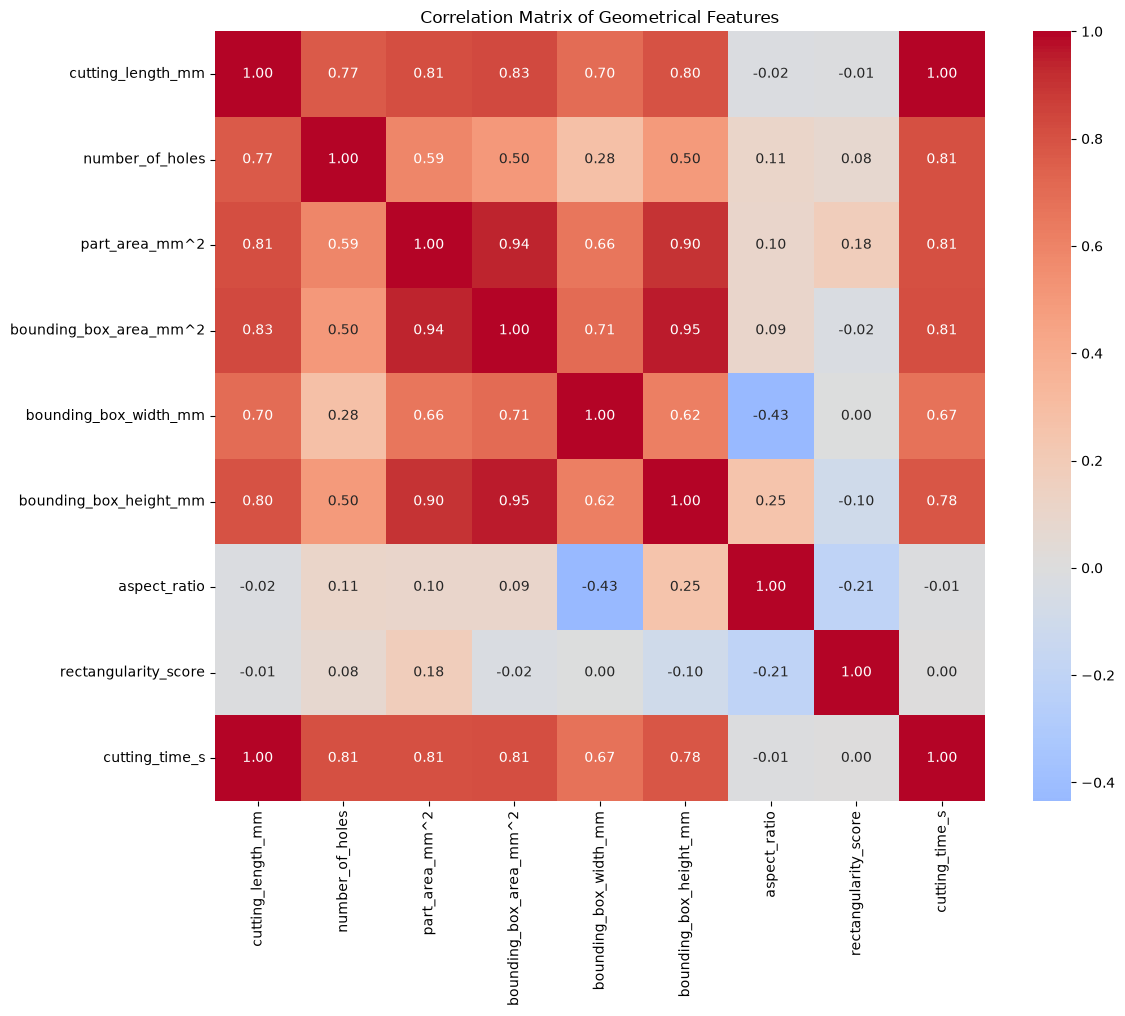

In [8]:
# plot correlation matrix
plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,          # displays correlation values
    cmap="coolwarm",     # uses a color gradient
    center=0,            # centers the colors at zero
    fmt=".2f",           # rounds values to two decimal places
    square=True          # makes cells square
)

plt.title("Correlation Matrix of Geometrical Features")
plt.tight_layout()
plt.show()

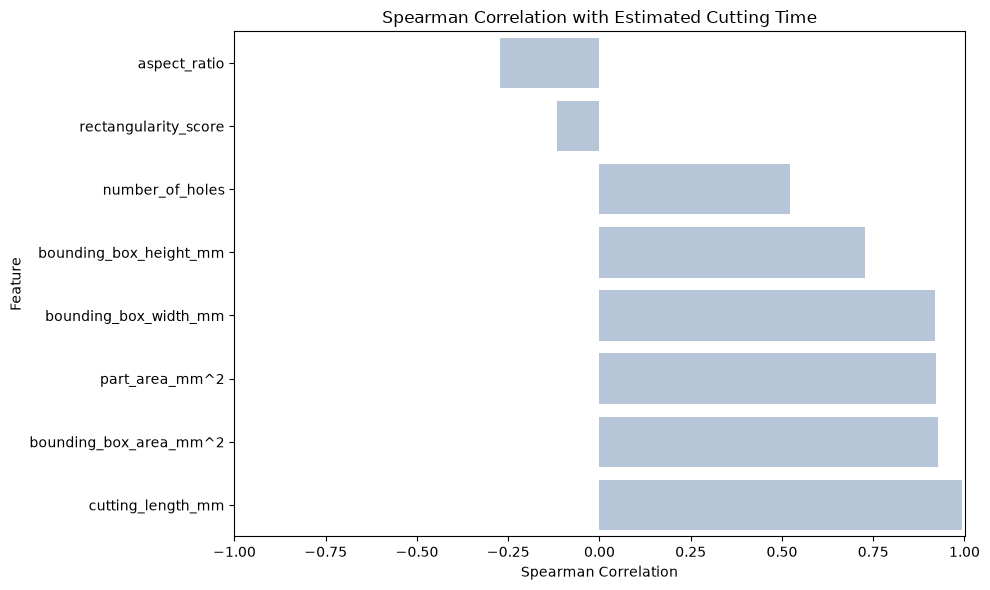

In [9]:
# calculate spearman correlation
spearman_matrix = correlation_df.corr(method="spearman")

# extract correlations with cutting time
spearman_corr = spearman_matrix["cutting_time_s"].drop(
    "cutting_time_s"
).sort_values()

# plot correlations
plt.figure(figsize=(10, 6))

sns.barplot(
    x=spearman_corr.values,
    y=spearman_corr.index,
    color="lightsteelblue"
)

plt.title("Spearman Correlation with Estimated Cutting Time")
plt.xlabel("Spearman Correlation")
plt.ylabel("Feature")
plt.xlim(-1, 1)

plt.tight_layout()
plt.show()